# Data check — all four transistor datasets

**Deliverable 3:** the Kirchhoff check for each case and three trend plots (OFF current vs temperature, OFF current vs
vth0, gate current vs toxe). A dataset summary is included first.

| Section | What it shows |
|---|---|
| 1. Dataset summary | rows, columns, missing values, duplicates, parameter ranges and bias voltages against the spec |
| 2. Kirchhoff check | `Id + Ig + Is + Ib ≈ 0` for every sample of every case |
| 3. Trend plots | OFF current vs temperature, OFF current vs vth0, gate current vs toxe, against the expected physics |
| 4. Summary | one pass / fail table for all checks |

**Files written to this folder:** `dataset_summary.csv`, `kirchhoff_check.csv`, `trend_check.csv` and the four figures
(`fig1_kirchhoff.png` … `fig4_gate_current_vs_toxe.png`).

**Datasets:** 20,000 samples per case, all drawn with seed `12175305`:
- NMOS: `NUM_SAMPLES = 20000`
- PMOS: the original 10,000 samples plus 10,000 more from the continued random sequence (`generate_pmos_20k.py`)

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repo root = first parent folder that contains Data_Generation/
ROOT = Path.cwd().resolve()
while not (ROOT / "Data_Generation").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Open this notebook from inside the DVD-Project repo")
    ROOT = ROOT.parent
DATA_DIR = ROOT / "Data_Generation" / "Datasets"
OUT_DIR  = ROOT / "Data_Generation" / "Data_Check"
MODEL_TEXT = (ROOT / "45nm_MGK.pm").read_text()

DATASETS = {"NMOS_ON": "NMOS_ON_20k.csv", "NMOS_OFF": "NMOS_OFF_20k.csv",
            "PMOS_ON": "PMOS_ON_20k.csv", "PMOS_OFF": "PMOS_OFF_20k.csv"}
SPEC_COLUMNS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj", "id", "ig", "is", "ib"]
CURRENTS = ["id", "ig", "is", "ib"]
PROCESS  = ["vth0", "toxe", "ndep", "u0", "xj"]
VDD_NOM, LMIN = 0.9, 45e-9
BIAS = {"NMOS_ON": ("vdd", "0"), "NMOS_OFF": ("0", "0"), "PMOS_ON": ("0", "vdd"), "PMOS_OFF": ("vdd", "vdd")}   # (Vg, Vb)

pd.set_option("display.float_format", lambda v: f"{v:.3g}")

# chart style
BLUE, LIGHT_BLUE, DARK_BLUE = "#2a78d6", "#9ec5f4", "#1c5cab"
RED, GRAY = "#c43d3c", "#8f8e8a"
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 10, "font.size": 9, "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(OUT_DIR / name, dpi=150, bbox_inches="tight")

data = {case: pd.read_csv(DATA_DIR / f) for case, f in DATASETS.items()}
for case, df in data.items():
    print(f"{case:9s} {DATASETS[case]:18s} {df.shape[0]} rows x {df.shape[1]} columns")

NMOS_ON   NMOS_ON_20k.csv    20000 rows x 16 columns
NMOS_OFF  NMOS_OFF_20k.csv   20000 rows x 16 columns
PMOS_ON   PMOS_ON_20k.csv    20000 rows x 16 columns
PMOS_OFF  PMOS_OFF_20k.csv   20000 rows x 16 columns


## 1. Dataset summary

Each check compares the data with the spec (Section 4 parameter ranges, gate / body voltages per case). Process
parameters are checked against ±10 % of the nominal values read from `45nm_MGK.pm`.

In [2]:
def nominal(kind):
    block = re.search(rf"(?ims)^\s*\.model\s+{kind}\b(.*?)(?=^\s*\.model\b|\Z)", MODEL_TEXT).group(1)
    return {p: float(re.search(rf"\b{p}\s*=\s*([-+0-9.eE]+)", block).group(1)) for p in PROCESS}

def within(s, lo, hi, tol=1e-9):
    lo, hi = min(lo, hi), max(lo, hi)
    return bool(((s >= lo - tol * abs(lo)) & (s <= hi + tol * abs(hi))).all())

summary = {}
for case, df in data.items():
    nom = nominal("nmos" if case.startswith("NMOS") else "pmos")
    level = lambda rule: df["vdd"] if rule == "vdd" else 0.0
    vg_rule, vb_rule = BIAS[case]
    summary[case] = {
        "rows": len(df),
        "columns in spec order": list(df.columns) == SPEC_COLUMNS,
        "no missing / infinite values": bool(np.isfinite(df.values).all()),
        "no duplicate rows": not df.duplicated().any(),
        "no zero currents": bool((df[CURRENTS] != 0).all().all()),
        "VDD within 0.9 V ±10 %": within(df["vdd"], 0.9 * VDD_NOM, 1.1 * VDD_NOM),
        "temperature within −40…125 °C": within(df["temp"], -40, 125),
        "W within 1…8 × Lmin": within(df["w"], LMIN, 8 * LMIN),
        "Vd, Vs within 0…VDD": bool(((df[["vd", "vs"]].min(axis=1) >= 0) & (df[["vd", "vs"]].max(axis=1) <= df["vdd"] + 1e-12)).all()),
        f"Vg, Vb as required": bool(np.allclose(df["vg"], level(vg_rule)) and np.allclose(df["vb"], level(vb_rule))),
        **{f"{p} within nominal ±10 %": within(df[p], 0.9 * nom[p], 1.1 * nom[p]) for p in PROCESS},
    }
summary = pd.DataFrame(summary)
summary.to_csv(OUT_DIR / "dataset_summary.csv")
summary.replace({True: "✓", False: "✗"})

,NMOS_ON,NMOS_OFF,PMOS_ON,PMOS_OFF
rows,20000,20000,20000,20000
columns in spec order,✓,✓,✓,✓
no missing / infinite values,✓,✓,✓,✓
no duplicate rows,✓,✓,✓,✓
no zero currents,✓,✓,✓,✓
VDD within 0.9 V ±10 %,✓,✓,✓,✓
temperature within −40…125 °C,✓,✓,✓,✓
W within 1…8 × Lmin,✓,✓,✓,✓
"Vd, Vs within 0…VDD",✓,✓,✓,✓
"Vg, Vb as required",✓,✓,✓,✓


## 2. Kirchhoff check

Charge cannot pile up inside the transistor, so the four terminal currents of every sample must sum to zero:

$$I_d + I_g + I_s + I_b = 0$$

This verifies that the simulation captured all four currents with a consistent sign convention, which is why every
terminal has its own voltage source in the netlist. The residual is shown both in amps and **relative to the largest
current of the same sample**, because the currents span many decades.

**Pass criterion:** relative residual below 1e-3 for every sample. SPICE solves to `reltol = 1e-6`, so residuals of
about 1e-6 are expected.

In [3]:
kcl = {}
for case, df in data.items():
    residual = df[CURRENTS].sum(axis=1).abs()
    largest  = df[CURRENTS].abs().max(axis=1)
    rel = residual / largest
    kcl[case] = rel
    kcl_row = {"max |Id+Ig+Is+Ib| (A)": residual.max(), "median relative": rel.median(),
               "99th pct relative": rel.quantile(0.99), "max relative": rel.max(), "pass (max relative < 1e-3)": rel.max() < 1e-3}
    kcl[case + "_row"] = kcl_row
kcl_table = pd.DataFrame({case: kcl[case + "_row"] for case in DATASETS}).T
kcl_table.to_csv(OUT_DIR / "kirchhoff_check.csv")
kcl_table

,max |Id+Ig+Is+Ib| (A),median relative,99th pct relative,max relative,pass (max relative < 1e-3)
NMOS_ON,9.92e-10,8.92e-07,6.48e-06,0.000358,True
NMOS_OFF,9.14e-13,8.16e-07,5.11e-06,8.41e-06,True
PMOS_ON,9.72e-10,8.13e-07,6.34e-06,9.15e-06,True
PMOS_OFF,9.1e-13,9.8e-07,8.24e-06,0.000221,True


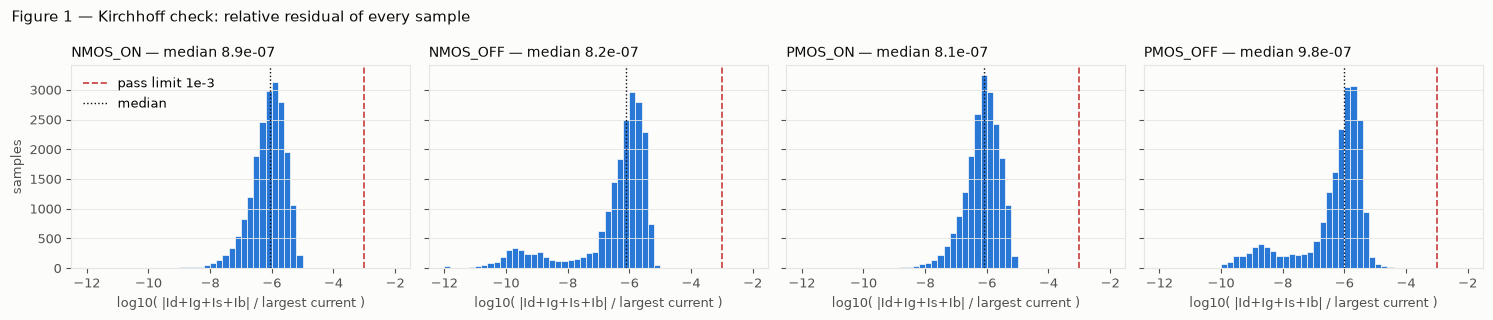

In [4]:
# Figure 1 — distribution of the relative Kirchhoff residual
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
bins = np.linspace(-12, -2, 51)
for ax, case in zip(axes, DATASETS):
    rel = np.log10(kcl[case].clip(lower=1e-12))
    ax.hist(rel, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
    ax.axvline(np.log10(1e-3), color=RED, lw=1.2, ls="--", label="pass limit 1e-3")
    ax.axvline(np.log10(kcl[case].median()), color=INK, lw=1, ls=":", label="median")
    ax.set_title(f"{case} — median {kcl[case].median():.1e}", loc="left")
    ax.set_xlabel("log10( |Id+Ig+Is+Ib| / largest current )")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("samples")
axes[0].legend(loc="upper left")
fig.suptitle("Figure 1 — Kirchhoff check: relative residual of every sample", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig1_kirchhoff.png")
plt.show()

## 3. Trend plots

Every input is random in every sample, so a scatter of one input against a current is wide. Each plot therefore shows
the samples faintly, with the **median** (line) and the **middle 50 %** (band) of the current in narrow bins of the
input, which makes the trend clear.

**OFF current:** the leakage through an OFF transistor, taken as the **larger of |Id| and |Is|**. At one of these two
terminals the channel leakage and the gate / junction leakage flow in the same direction and add up; at the other
they partly cancel. Only samples with |Vds| ≥ VDD / 2 are used, so the leakage is not limited by a tiny Vds.

| Trend | Expected physics |
|---|---|
| OFF current vs temperature | **rises** steeply: the thermal voltage kT/q grows and Vth drops, and sub-threshold current ∝ exp(−Vth / (n·kT/q)) |
| OFF current vs \|vth0\| | **falls**: a higher threshold voltage exponentially reduces sub-threshold leakage |
| Gate current vs toxe | **falls**: direct tunnelling through the gate oxide drops exponentially with oxide thickness |

In [5]:
def off_current(df):
    keep = (df["vd"] - df["vs"]).abs() >= df["vdd"] / 2
    sub = df[keep]
    return sub, np.maximum(sub["id"].abs(), sub["is"].abs())

def binned(x, y, edges):
    # median and quartiles of log10(y) in bins of x
    logy, idx = np.log10(y), np.digitize(x, edges) - 1
    rows = [(0.5 * (edges[k] + edges[k + 1]), *np.percentile(logy[idx == k], [25, 50, 75]))
            for k in range(len(edges) - 1) if (idx == k).sum() >= 20]
    return pd.DataFrame(rows, columns=["x", "q25", "q50", "q75"])

def trend_panel(ax, x, y, edges, color=BLUE, label=None, scatter=True):
    if scatter:
        ax.scatter(x, y, s=2, alpha=0.08, color=LIGHT_BLUE, linewidths=0, rasterized=True)
    b = binned(np.asarray(x), np.asarray(y), edges)
    ax.fill_between(b["x"], 10 ** b["q25"], 10 ** b["q75"], color=color, alpha=0.18, linewidth=0)
    ax.plot(b["x"], 10 ** b["q50"], color=color, lw=2, label=label)
    ax.set_yscale("log")
    return b

trend_rows = []
def add_trend(case, name, expected, x, y, b):
    rho = pd.Series(np.asarray(x)).corr(pd.Series(np.log10(np.asarray(y))), method="spearman")
    ratio = 10 ** (b["q50"].iloc[-1] - b["q50"].iloc[0])
    ok = rho > 0 if expected == "rises" else rho < 0
    trend_rows.append({"case": case, "trend": name, "expected": expected, "Spearman rho": rho,
                       "median ratio (last bin / first bin)": ratio, "pass": ok})

### Trend 1 — OFF current vs temperature

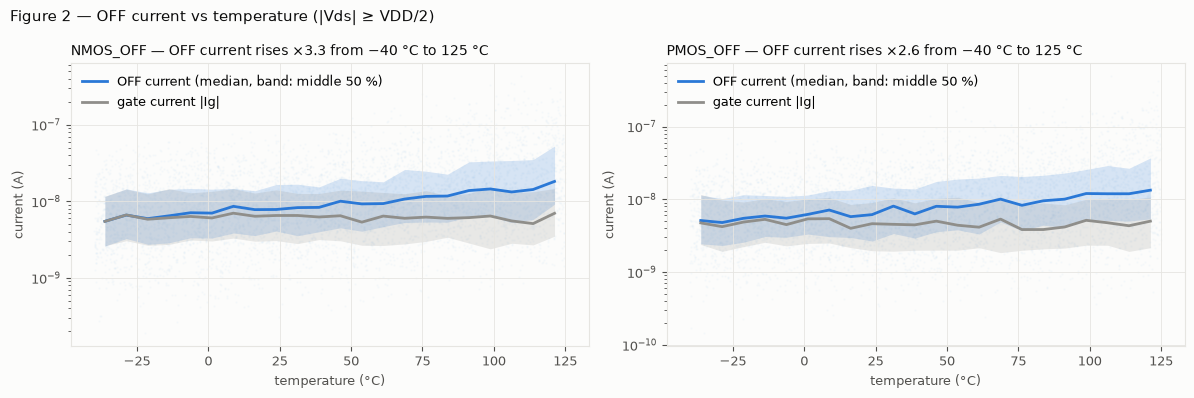

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
edges = np.linspace(-40, 125, 23)
for ax, case in zip(axes, ["NMOS_OFF", "PMOS_OFF"]):
    sub, ioff = off_current(data[case])
    b = trend_panel(ax, sub["temp"], ioff, edges, label="OFF current (median, band: middle 50 %)")
    trend_panel(ax, sub["temp"], sub["ig"].abs(), edges, color=GRAY, label="gate current |Ig|", scatter=False)
    add_trend(case, "OFF current vs temperature", "rises", sub["temp"], ioff, b)
    ratio = 10 ** (b["q50"].iloc[-1] - b["q50"].iloc[0])
    ax.set(xlabel="temperature (°C)", ylabel="current (A)")
    ax.set_title(f"{case} — OFF current rises ×{ratio:.1f} from −40 °C to 125 °C", loc="left")
    ax.legend(loc="upper left")
fig.suptitle("Figure 2 — OFF current vs temperature (|Vds| ≥ VDD/2)", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig2_off_current_vs_temperature.png")
plt.show()

**Why the OFF current rises only a few times.** The gate oxide in this 45 nm model is only ~0.9 nm thick, so gate
tunnelling is about as large as the whole OFF current, and it hardly changes with temperature (grey curve above, table
below; cold = below −20 °C, hot = above 105 °C). Only the sub-threshold channel part rises steeply with temperature:

- at low temperature the OFF current is almost pure gate current;
- at high temperature the sub-threshold part becomes comparable, so the total rises a few times.

The same reason makes the vth0 trend (next) modest: vth0 only changes the sub-threshold part.

In [7]:
rows = []
for case in ["NMOS_OFF", "PMOS_OFF"]:
    sub, ioff = off_current(data[case])
    ig = sub["ig"].abs()
    cold, hot = sub["temp"] < -20, sub["temp"] > 105
    rows.append({"case": case, "median |Ig| / OFF current": np.median(ig / ioff),
                 "OFF current: median hot / cold": np.median(ioff[hot]) / np.median(ioff[cold]),
                 "|Ig|: median hot / cold": np.median(ig[hot]) / np.median(ig[cold])})
pd.DataFrame(rows).set_index("case")

,median |Ig| / OFF current,OFF current: median hot / cold,|Ig|: median hot / cold
case,,,
NMOS_OFF,0.978,2.47,1.04
PMOS_OFF,0.94,2.44,1.02


### Trend 2 — OFF current vs |vth0|

Temperature changes the OFF current far more than the ±10 % vth0 range does, so the vth0 trend is shown separately for
three temperature bands. Within each band the OFF current falls as |vth0| rises.

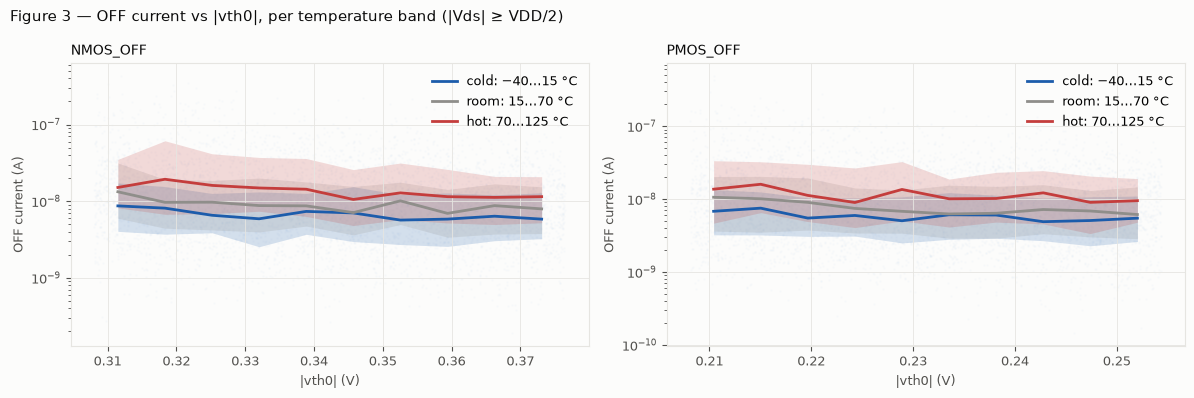

In [8]:
BANDS = [("cold: −40…15 °C", -40, 15, DARK_BLUE), ("room: 15…70 °C", 15, 70, GRAY), ("hot: 70…125 °C", 70, 125, RED)]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, case in zip(axes, ["NMOS_OFF", "PMOS_OFF"]):
    sub, ioff = off_current(data[case])
    vth = sub["vth0"].abs()
    edges = np.linspace(vth.min(), vth.max(), 11)
    ax.scatter(vth, ioff, s=2, alpha=0.06, color=LIGHT_BLUE, linewidths=0, rasterized=True)
    for label, lo, hi, color in BANDS:
        m = (sub["temp"] >= lo) & (sub["temp"] < hi)
        b = trend_panel(ax, vth[m], ioff[m], edges, color=color, label=label, scatter=False)
        add_trend(case, f"OFF current vs |vth0| ({label.split(':')[0]})", "falls", vth[m], ioff[m], b)
    ax.set(xlabel="|vth0| (V)", ylabel="OFF current (A)")
    ax.set_title(case, loc="left")
    ax.legend(loc="upper right")
fig.suptitle("Figure 3 — OFF current vs |vth0|, per temperature band (|Vds| ≥ VDD/2)", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig3_off_current_vs_vth0.png")
plt.show()

### Trend 3 — gate current vs toxe

All samples of each case. Gate current is largest in the ON cases, where the full supply voltage sits across the oxide.

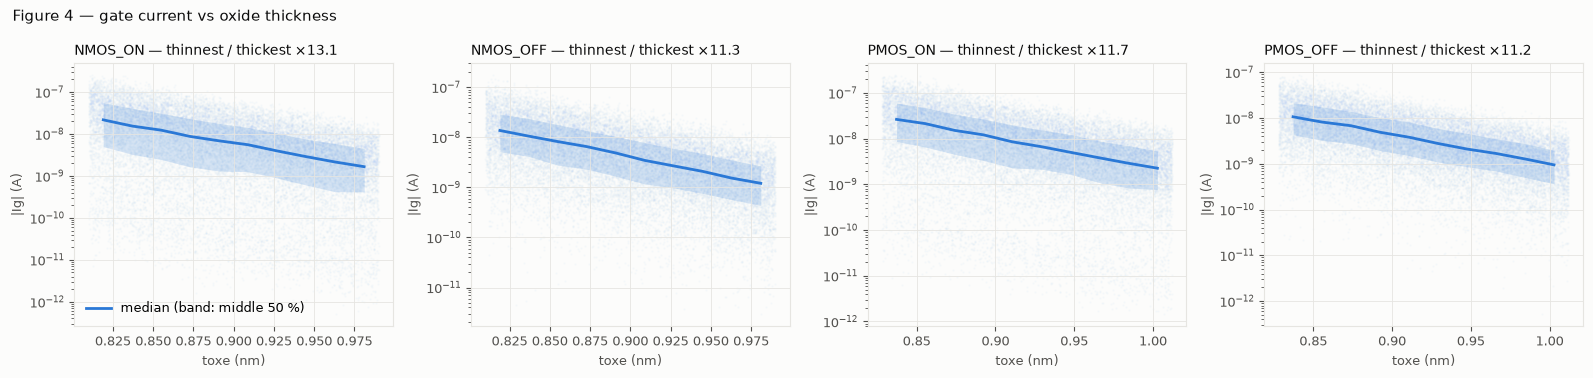

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, case in zip(axes, DATASETS):
    df = data[case]
    toxe_nm, ig = df["toxe"] * 1e9, df["ig"].abs()
    edges = np.linspace(toxe_nm.min(), toxe_nm.max(), 11)
    b = trend_panel(ax, toxe_nm, ig, edges, label="median (band: middle 50 %)")
    add_trend(case, "gate current vs toxe", "falls", toxe_nm, ig, b)
    ratio = 10 ** (b["q50"].iloc[0] - b["q50"].iloc[-1])
    ax.set(xlabel="toxe (nm)", ylabel="|Ig| (A)")
    ax.set_title(f"{case} — thinnest / thickest ×{ratio:.1f}", loc="left")
axes[0].legend(loc="lower left")
fig.suptitle("Figure 4 — gate current vs oxide thickness", color=INK, fontsize=11, x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig4_gate_current_vs_toxe.png")
plt.show()

## 4. Summary

**Spearman ρ** measures whether the current consistently rises (ρ > 0) or falls (ρ < 0) with the input, on a rank
basis. The ratio compares the median current in the last bin with the first bin.

In [10]:
trend_table = pd.DataFrame(trend_rows).set_index(["case", "trend"])
trend_table.to_csv(OUT_DIR / "trend_check.csv")
display(trend_table.replace({True: "✓", False: "✗"}))

print(f"Dataset summary: all checks pass for all cases: {bool(summary.drop(index='rows').all().all())}")
print(f"Kirchhoff check: all cases pass: {bool(kcl_table['pass (max relative < 1e-3)'].all())}")
print(f"Trend checks: {int(trend_table['pass'].sum())} / {len(trend_table)} match the expected physics")

expected  Spearman rho  \
case     trend                                                 
NMOS_OFF OFF current vs temperature      rises         0.269   
PMOS_OFF OFF current vs temperature      rises         0.246   
NMOS_OFF OFF current vs |vth0| (cold)    falls       -0.0951   
         OFF current vs |vth0| (room)    falls        -0.113   
         OFF current vs |vth0| (hot)     falls         -0.15   
PMOS_OFF OFF current vs |vth0| (cold)    falls       -0.0727   
         OFF current vs |vth0| (room)    falls       -0.0998   
         OFF current vs |vth0| (hot)     falls       -0.0979   
NMOS_ON  gate current vs toxe            falls        -0.411   
NMOS_OFF gate current vs toxe            falls        -0.524   
PMOS_ON  gate current vs toxe            falls        -0.464   
PMOS_OFF gate current vs toxe            falls        -0.547   

                                       median ratio (last bin / first bin)  \
case     trend                                                               
NMOS_OFF OFF current vs temperature                                   3.32   
PMOS_OFF OFF current vs temperature                                   2.61   
NMOS_OFF OFF current vs |vth0| (cold)                                0.672   
         OFF current vs |vth0| (room)                                0.598   
         OFF current vs |vth0| (hot)                                 0.759   
PMOS_OFF OFF current vs |vth0| (cold)                                0.805   
         OFF current vs |vth0| (room)                                0.579   
         OFF current vs |vth0| (hot)                                 0.695   
NMOS_ON  gate current vs toxe                                       0.0765   
NMOS_OFF gate current vs toxe                                       0.0881   
PMOS_ON  gate current vs toxe                                       0.0855   
PMOS_OFF gate current vs toxe                                       0.0891   

                                      pass  
case     trend                              
NMOS_OFF OFF current vs temperature      ✓  
PMOS_OFF OFF current vs temperature      ✓  
NMOS_OFF OFF current vs |vth0| (cold)    ✓  
         OFF current vs |vth0| (room)    ✓  
         OFF current vs |vth0| (hot)     ✓  
PMOS_OFF OFF current vs |vth0| (cold)    ✓  
         OFF current vs |vth0| (room)    ✓  
         OFF current vs |vth0| (hot)     ✓  
NMOS_ON  gate current vs toxe            ✓  
NMOS_OFF gate current vs toxe            ✓  
PMOS_ON  gate current vs toxe            ✓  
PMOS_OFF gate current vs toxe            ✓

Dataset summary: all checks pass for all cases: True
Kirchhoff check: all cases pass: True
Trend checks: 12 / 12 match the expected physics
